___
<h1> Machine Learning </h1>
<h2> M. Sc. in Electrical and Computer Engineering </h2>
<h3> Instituto Superior de Engenharia / Universidade do Algarve </h3>

[MEEC](https://ise.ualg.pt/en/curso/1477) / [ISE](https://ise.ualg.pt) / [UAlg](https://www.ualg.pt)

Pedro J. S. Cardoso (pcardoso@ualg.pt)
___


# Support vector machines (SVMs)

An SVM draws a **margin** around a decision boundary. The same idea is used for classification (`SVC`), regression (`SVR` / `LinearSVR`) and outlier detection.

We start with **Iris** (three species). Then we use an SVM to predict a number: hourly bike rentals in Seoul.

Docs: [sklearn SVM](https://scikit-learn.org/stable/modules/svm.html) and the [mathematical formulation](https://scikit-learn.org/stable/modules/svm.html#svm-mathematical-formulation).


## Classification

Iris has **three** classes. We split into train and test, then fit `StandardScaler` **only on the training set** by putting it in a pipeline (same rule as for the ANN).


In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

iris = load_iris()

X_train, X_test, y_train, y_test = train_test_split(
    iris.data, 
    iris.target, 
    random_state=42
)

`C` is the soft-margin parameter from the slides. Large `C`: few mistakes, a tighter margin. Scale the features first: SVM distances (and RBF `gamma`) depend on feature units.


In [2]:
svm = make_pipeline(
    StandardScaler(),
    SVC(C=1, kernel="rbf", gamma="scale"),
)
svm.fit(X_train, y_train)

print("Accuracy:", svm.score(X_test, y_test))

Accuracy: 1.0


### Kernels (the figure on the slides)

The four plots below use only **sepal length** and **sepal width**, so we can draw the regions. They are **not** a train/test evaluation: every point is shown, as in the [sklearn gallery](https://scikit-learn.org/stable/auto_examples/svm/plot_iris_svc.html).

Linear cuts are planes. RBF and polynomial bend the regions. `LinearSVC` solves a slightly different linear problem from `SVC(kernel="linear")`, so the two linear panels are not identical.


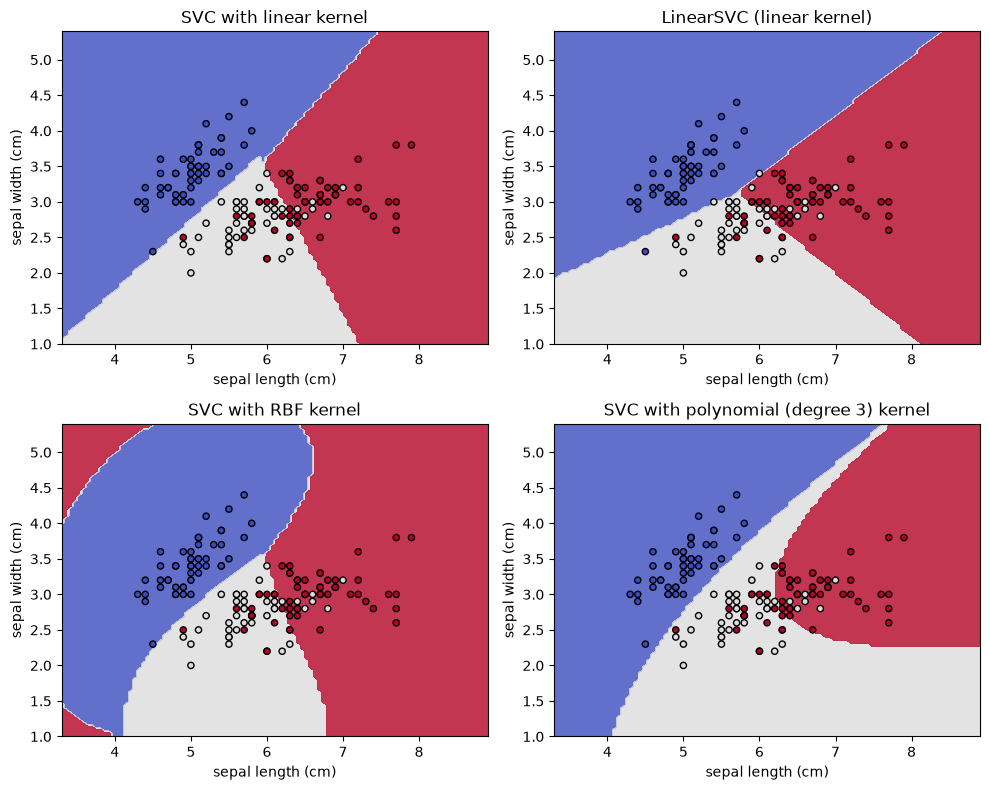

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import LinearSVC

X2 = iris.data[:, :2]
y = iris.target

models = (
    SVC(kernel="linear", C=1),
    LinearSVC(C=1, max_iter=10_000),
    SVC(kernel="rbf", gamma=0.7, C=1),
    SVC(kernel="poly", degree=3, gamma="auto", C=1),
)
titles = (
    "SVC with linear kernel",
    "LinearSVC (linear kernel)",
    "SVC with RBF kernel",
    "SVC with polynomial (degree 3) kernel",
)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for clf, title, ax in zip(models, titles, axes.ravel()):
    clf.fit(X2, y)
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X2,
        response_method="predict",
        multiclass_colors="coolwarm",
        alpha=0.8,
        ax=ax,
        xlabel=iris.feature_names[0],
        ylabel=iris.feature_names[1],
    )
    ax.scatter(
        X2[:, 0], X2[:, 1], c=y,
        cmap=ListedColormap(disp.multiclass_colors_),
        s=20, edgecolors="k",
    )
    ax.set_title(title)

fig.tight_layout()


### Soft margin: `C` and support vectors

Two classes, two features, a linear SVM. Small `C` allows more points inside the margin; large `C` hugs the data. The circled points are **support vectors**: they are the only ones that define $\beta$.


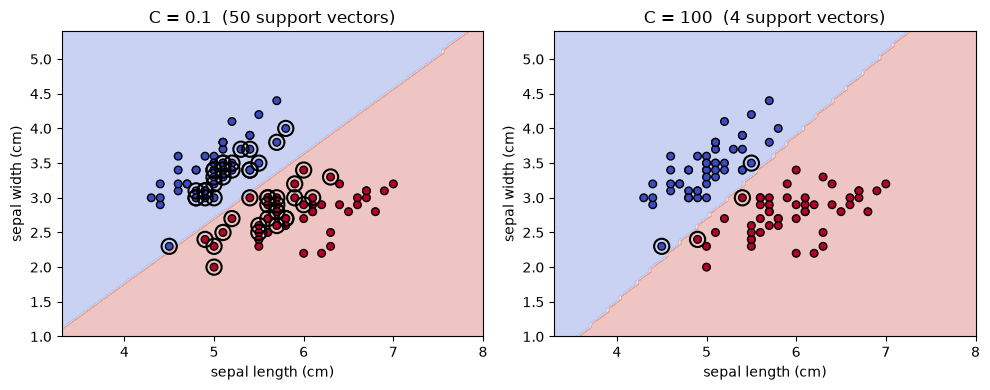

In [4]:
mask = iris.target < 2
X_bin = iris.data[mask][:, :2]
y_bin = iris.target[mask]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for C, ax in zip([0.1, 100], axes):
    clf = SVC(kernel="linear", C=C).fit(X_bin, y_bin)
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X_bin,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.3,
        ax=ax,
        xlabel=iris.feature_names[0],
        ylabel=iris.feature_names[1],
    )
    ax.scatter(X_bin[:, 0], X_bin[:, 1], c=y_bin, cmap=plt.cm.coolwarm, s=30, edgecolors="k")
    sv = clf.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolors="none", edgecolors="k", linewidths=1.5)
    ax.set_title(f"C = {C}  ({clf.n_support_.sum()} support vectors)")

fig.tight_layout()


A test accuracy of $1.0$ on 38 Iris points is **luck** (or a too-easy split), not a proof that the model is perfect. Change `random_state` in `train_test_split` and the score will move.


## Regression

The same margin idea predicts a number: `SVR` (kernels) or `LinearSVR` (linear, faster).

We use the Seoul Bike Sharing Demand dataset: hourly rental counts in Seoul, 2017–2018, with weather and season. Source: https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand (already in `./data`).


In [5]:
import pandas as pd

df = pd.read_csv("./data/SeoulBikeData.csv")
df.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


No missing values, but a few categorical columns:


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   object 
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(C)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)   8760 non-null   float64
 9   Rainfall(mm)              8760 non-null   float64
 10  Snowfall (cm)             8760 non-null   float64
 11  Seasons                   8760 non-null   object 
 12  Holiday                   8760 non-null   object 
 13  Functioning Day           8760 non-null   object 
dtypes: float

Turn `Seasons`, `Holiday` and `Functioning Day` into dummy (0/1) columns. `drop_first=True` drops one level per variable so the columns are not a linear combination of each other.


In [7]:
df = pd.get_dummies(df, columns=["Seasons", "Holiday", "Functioning Day"], drop_first=True)
df.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_No Holiday,Functioning Day_Yes
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,False,False,True,True,True
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,False,False,True,True,True
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,False,False,True,True,True
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,False,False,True,True,True
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,False,False,True,True,True


Split `Date` into month, day and day of week, then drop the original column.


In [8]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df["month"] = df["Date"].dt.month
df["day"] = df["Date"].dt.day
df["day_of_week"] = df["Date"].dt.day_of_week
df = df.drop(columns="Date")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rented Bike Count         8760 non-null   int64  
 1   Hour                      8760 non-null   int64  
 2   Temperature(C)            8760 non-null   float64
 3   Humidity(%)               8760 non-null   int64  
 4   Wind speed (m/s)          8760 non-null   float64
 5   Visibility (10m)          8760 non-null   int64  
 6   Dew point temperature(C)  8760 non-null   float64
 7   Solar Radiation (MJ/m2)   8760 non-null   float64
 8   Rainfall(mm)              8760 non-null   float64
 9   Snowfall (cm)             8760 non-null   float64
 10  Seasons_Spring            8760 non-null   bool   
 11  Seasons_Summer            8760 non-null   bool   
 12  Seasons_Winter            8760 non-null   bool   
 13  Holiday_No Holiday        8760 non-null   bool   
 14  Function

Target: `Rented Bike Count`. Shuffle before the split so the last months of the year are not all in the test set.


In [9]:
X = df.drop(columns="Rented Bike Count")
y = df["Rented Bike Count"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    shuffle=True, 
    random_state=42, 
    test_size=0.2
)

Temperature, humidity and visibility are on very different scales. Fit the scaler on **train only**, inside the pipeline.

`LinearSVR` is the fast linear model. Use it first; `SVR` with an RBF kernel is much slower on thousands of rows.


In [10]:
from sklearn.svm import LinearSVR, SVR

linear_svr = make_pipeline(
    StandardScaler(),
    LinearSVR(C=1, max_iter=10_000),
)
linear_svr.fit(X_train, y_train)
print("LinearSVR R^2 (test):", linear_svr.score(X_test, y_test))


LinearSVR R^2 (test): 0.46586944067219915


RBF `SVR` on the full training set is slow. Search `C` and the kernel on a **subset**, then refit the winner on all of `X_train`.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.utils import resample

X_small, y_small = resample(X_train, y_train, n_samples=1500, random_state=42)

pipe = make_pipeline(
    StandardScaler(), 
    SVR()
)

param_grid = [
    {
        "svr__kernel": ["linear"], 
        "svr__C": [1, 10]
    },
    {
        "svr__kernel": ["rbf"], 
        "svr__C": [1, 10], 
        "svr__gamma": ["scale"]
    },
]

gs = GridSearchCV(
    pipe,
    param_grid,
    cv=3,
    n_jobs=-1,
    verbose=1,
).fit(X_small, y_small)

print("best params (subset):", gs.best_params_)
print("best CV R^2 (subset):", gs.best_score_)

model = clone(gs.best_estimator_).fit(X_train, y_train)
print("test R^2:", model.score(X_test, y_test))


Fitting 3 folds for each of 4 candidates, totalling 12 fits
best params (subset): {'svr__C': 10, 'svr__kernel': 'linear'}
best CV R^2 (subset): 0.4844494090449696


On a perfect regression the points would lie on the diagonal.


In [ ]:
pred = model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.plot(y_test.values, pred, "o", c="g", alpha=0.4, markersize=4)
plt.plot([0, 3500], [0, 3500], "r")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs predicted (test)")
plt.gca().set_aspect("equal", adjustable="box")


## Your turn

- **Digits** (`sklearn.datasets.load_digits`): many pixels, a natural SVM test. Pipeline: `StandardScaler` + `SVC`. Compare `kernel="linear"` and `kernel="rbf"`.
- **Wine quality**: https://archive.ics.uci.edu/ml/datasets/Wine+Quality — classification or regression, same `C` / kernel story.
